In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("C:\\Users\\ABHINAV AR\\fraud_data.xlsx")

df.head()

,transaction_id,customer_id,transaction_time,amount,merchant_category,merchant_location,customer_location,payment_method,device_type,ip_country,distance_from_home_km,previous_transactions_24h,failed_login_attempts,card_present,is_weekend,transaction_velocity,is_fraud
0,T00001,C1000,2026-07-01 23:06,224,Fuel,Malacca,Kuala Lumpur,Online Banking,Mobile,MY,47,3,1,Yes,Yes,2,0
1,T00002,C1001,2026-07-02 07:28,40495,Electronics,Malacca,Johor,Debit Card,Mobile,SG,2269,51,6,Yes,No,8,1
2,T00003,C1002,2026-07-03 03:22,1293,Grocery,Johor,Malacca,UPI,Mobile,MY,13,7,1,Yes,No,1,0
3,T00004,C1003,2026-07-04 20:39,7991,Online Shopping,Johor,Malacca,Credit Card,POS,MY,24,14,0,Yes,Yes,5,0
4,T00005,C1004,2026-07-05 20:53,39871,Jewelry,Johor,Penang,UPI,Web,GB,1385,27,2,Yes,Yes,15,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   transaction_id             100 non-null    object
 1   customer_id                100 non-null    object
 2   transaction_time           100 non-null    object
 3   amount                     100 non-null    int64 
 4   merchant_category          100 non-null    object
 5   merchant_location          100 non-null    object
 6   customer_location          100 non-null    object
 7   payment_method             100 non-null    object
 8   device_type                100 non-null    object
 9   ip_country                 100 non-null    object
 10  distance_from_home_km      100 non-null    int64 
 11  previous_transactions_24h  100 non-null    int64 
 12  failed_login_attempts      100 non-null    int64 
 13  card_present               100 non-null    object
 14  is_weekend 

In [4]:
df.shape

(100, 17)

In [5]:
df.describe()

,amount,distance_from_home_km,previous_transactions_24h,failed_login_attempts,transaction_velocity,is_fraud
count,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000
mean,13723.350000,298.810000,12.57000,1.370000,5.480000,0.180000
std,24310.041162,678.421515,11.23959,1.983034,4.639488,0.386123
min,224.000000,3.000000,1.00000,0.000000,1.000000,0.000000
25%,2672.250000,22.000000,6.00000,0.000000,2.750000,0.000000
50%,4834.500000,36.000000,11.00000,1.000000,4.000000,0.000000
75%,7403.250000,48.000000,14.00000,1.000000,6.000000,0.000000
max,115710.000000,2987.000000,60.00000,8.000000,21.000000,1.000000


In [7]:
df.isnull().sum()
df.duplicated().sum()

0

In [8]:
df = df.drop_duplicates()

In [10]:
df["transaction_time"] = pd.to_datetime(df["transaction_time"])

df["transaction_hour"] = df["transaction_time"].dt.hour

df["day_of_week"] = df["transaction_time"].dt.dayofweek

df.head()

,transaction_id,customer_id,transaction_time,amount,merchant_category,merchant_location,customer_location,payment_method,device_type,ip_country,distance_from_home_km,previous_transactions_24h,failed_login_attempts,card_present,is_weekend,transaction_velocity,is_fraud,transaction_hour,day_of_week
0,T00001,C1000,2026-07-01 23:06:00,224,Fuel,Malacca,Kuala Lumpur,Online Banking,Mobile,MY,47,3,1,Yes,Yes,2,0,23,2
1,T00002,C1001,2026-07-02 07:28:00,40495,Electronics,Malacca,Johor,Debit Card,Mobile,SG,2269,51,6,Yes,No,8,1,7,3
2,T00003,C1002,2026-07-03 03:22:00,1293,Grocery,Johor,Malacca,UPI,Mobile,MY,13,7,1,Yes,No,1,0,3,4
3,T00004,C1003,2026-07-04 20:39:00,7991,Online Shopping,Johor,Malacca,Credit Card,POS,MY,24,14,0,Yes,Yes,5,0,20,5
4,T00005,C1004,2026-07-05 20:53:00,39871,Jewelry,Johor,Penang,UPI,Web,GB,1385,27,2,Yes,Yes,15,1,20,6


In [ ]:
df = df.drop(columns=[
    "transaction_id",
    "customer_id",
    "transaction_time"
])

In [12]:
X = df.drop("is_fraud", axis=1)

y = df["is_fraud"]

X.head()

y.head()

0    0
1    1
2    0
3    0
4    1
Name: is_fraud, dtype: int64

In [13]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

X.head()

,amount,distance_from_home_km,previous_transactions_24h,failed_login_attempts,transaction_velocity,transaction_hour,day_of_week,merchant_category_Electronics,merchant_category_Fuel,merchant_category_Grocery,...,payment_method_Debit Card,payment_method_Online Banking,payment_method_UPI,device_type_POS,device_type_Web,ip_country_MY,ip_country_SG,ip_country_US,card_present_Yes,is_weekend_Yes
0,224,47,3,1,2,23,2,0,1,0,...,0,1,0,0,0,1,0,0,1,1
1,40495,2269,51,6,8,7,3,1,0,0,...,1,0,0,0,0,0,1,0,1,0
2,1293,13,7,1,1,3,4,0,0,1,...,0,0,1,0,0,1,0,0,1,0
3,7991,24,14,0,5,20,5,0,0,0,...,0,0,0,1,0,1,0,0,1,1
4,39871,1385,27,2,15,20,6,0,0,0,...,0,0,1,0,1,0,0,0,1,1


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80, 32)
Testing data: (20, 32)


In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [16]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0]

Predicted values:
[0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0]


In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 1.0


In [18]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00         4

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [21]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[16  0]
 [ 0  4]]


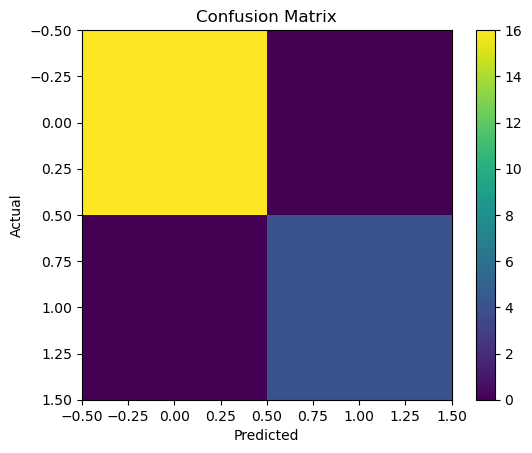

In [22]:
cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

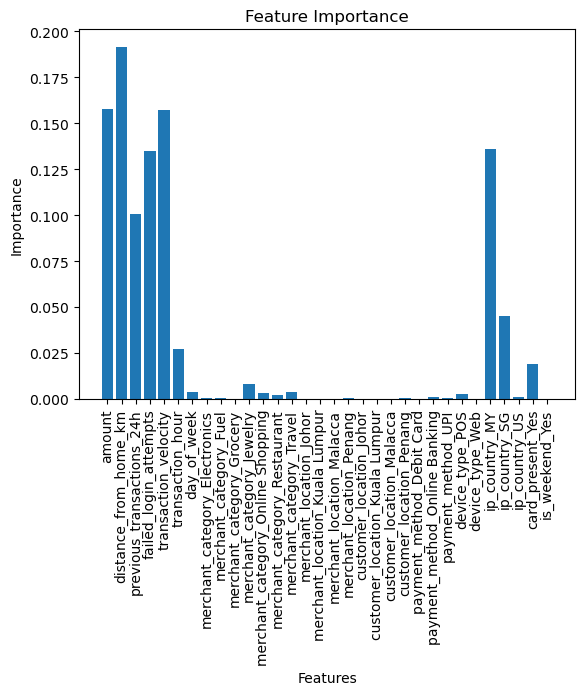

In [23]:
plt.bar(X_train.columns, model.feature_importances_)

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=90)
plt.show()

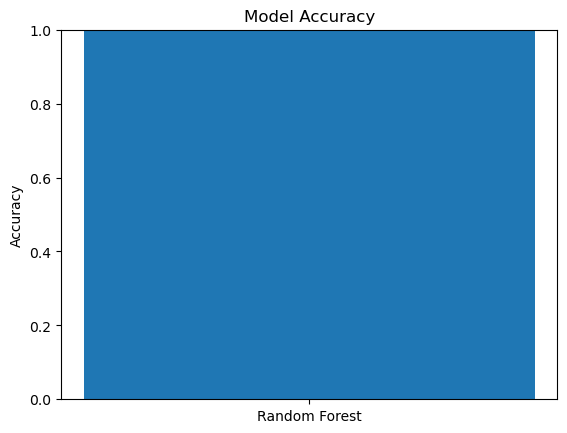

In [24]:
plt.bar(["Random Forest"], [accuracy])

plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()